# TC3-46 — Análise de Relações entre Variáveis

**Objetivo:** investigar associações entre as variáveis da base consolidada e o target `alfabetizado`, utilizando análises e visualizações adequadas aos tipos de dados.

**Escopo deste notebook**
- Ler a base consolidada particionada por UF, sem juntar manualmente os arquivos.
- Verificar estrutura, tipos, valores ausentes e distribuição do target.
- Explorar relações entre variáveis numéricas e entre variáveis selecionadas e o target.
- Explorar relações com variáveis categóricas de baixa cardinalidade.
- Registrar achados e limitações para apoiar a próxima etapa de modelagem.

**Cuidados metodológicos**
- Associação não implica causalidade.
- Correlação linear não captura todos os tipos de relação.
- Identificadores (`id_aluno`, `id_escola`, `id_municipio`, quando presentes) não devem ser interpretados automaticamente como variáveis explicativas.
- Variáveis construídas com informação do próprio target ou do mesmo período podem gerar *data leakage*. Os resultados deste notebook são exploratórios, não uma aprovação automática das variáveis para treinamento.
- Como a base tem milhões de linhas, algumas visualizações usam amostra e as agregações são feitas antes de plotar.


## 1. Preparação do ambiente

O notebook usa Polars para consultar os arquivos Parquet de forma eficiente e pandas/matplotlib/seaborn para tabelas e visualizações. Se alguma biblioteca não estiver instalada, instale-a no ambiente do projeto antes de continuar.


In [29]:
from pathlib import Path
import warnings

import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
sns.set_theme()

print("Polars:", pl.__version__)
print("Pandas:", pd.__version__)


Polars: 2.0.0
Pandas: 3.0.6


## 2. Localização e leitura dos arquivos

A estrutura esperada é:

`dados/consolidado/base_alunos_municipios_por_uf/sigla_uf=SP/00000000.parquet`

O código procura a pasta a partir do diretório atual e de seus diretórios pais. Se estiver executando o notebook fora da raiz do repositório, ajuste `PROJECT_ROOT` manualmente.


In [30]:
def encontrar_raiz_projeto(inicio: Path) -> Path | None:
    inicio = inicio.resolve()
    for candidato in [inicio, *inicio.parents]:
        base = candidato / "dados" / "consolidado" / "base_alunos_municipios_por_uf"
        if base.exists():
            return candidato
    return None

PROJECT_ROOT = encontrar_raiz_projeto(Path.cwd())

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Não encontrei dados/consolidado/base_alunos_municipios_por_uf. "
        "Defina PROJECT_ROOT manualmente para a raiz do repositório."
    )

BASE_PATH = PROJECT_ROOT / "dados" / "consolidado" / "base_alunos_municipios_por_uf"
arquivos_parquet = sorted(BASE_PATH.glob("sigla_uf=*/00000000.parquet"))

print("Raiz do projeto:", PROJECT_ROOT)
print("Pasta da base:", BASE_PATH)
print("Quantidade de arquivos Parquet:", len(arquivos_parquet))
print("Exemplos:", [str(p.relative_to(PROJECT_ROOT)) for p in arquivos_parquet[:5]])

if not arquivos_parquet:
    raise FileNotFoundError(f"Nenhum Parquet encontrado em {BASE_PATH}")

# Lazy scan: o Polars consulta os arquivos sem carregar tudo imediatamente.
lf = pl.scan_parquet(str(BASE_PATH / "sigla_uf=*/00000000.parquet"))
print("Esquema detectado:")
print(lf.collect_schema())


Raiz do projeto: C:\Users\sandr\POS-TECH\Fase 3\tech_challenge_3
Pasta da base: C:\Users\sandr\POS-TECH\Fase 3\tech_challenge_3\dados\consolidado\base_alunos_municipios_por_uf
Quantidade de arquivos Parquet: 26
Exemplos: ['dados\\consolidado\\base_alunos_municipios_por_uf\\sigla_uf=AC\\00000000.parquet', 'dados\\consolidado\\base_alunos_municipios_por_uf\\sigla_uf=AL\\00000000.parquet', 'dados\\consolidado\\base_alunos_municipios_por_uf\\sigla_uf=AM\\00000000.parquet', 'dados\\consolidado\\base_alunos_municipios_por_uf\\sigla_uf=AP\\00000000.parquet', 'dados\\consolidado\\base_alunos_municipios_por_uf\\sigla_uf=BA\\00000000.parquet']
Esquema detectado:
Schema({'id_aluno': String, 'id_escola': String, 'id_municipio': Int64, 'nome_municipio': String, 'sigla_uf': String, 'ano_referencia': Int64, 'serie': Int32, 'rede': Int32, 'rede_descricao': String, 'caderno': String, 'presenca': Int32, 'preenchimento_caderno': Int32, 'proficiencia': Float64, 'peso_aluno': Float64, 'taxa_alfabetizacao_m

## 3. Dimensão e visão geral

Esta célula calcula a quantidade de registros e colunas. Pode levar algum tempo, pois consulta todos os arquivos.


In [31]:
# Consulta agregada sobre todos os arquivos.
resumo_dimensoes = lf.select([
    pl.len().alias("registros"),
    pl.lit(len(lf.collect_schema().names())).alias("colunas")
]).collect()

display(resumo_dimensoes.to_pandas())


,registros,colunas
0,3867999,49


## 4. Tipos de dados e valores ausentes

A tabela de nulos ajuda a identificar variáveis que exigem cuidado. Percentuais altos de nulos podem refletir cobertura desigual entre anos/fontes, mas essa hipótese deve ser conferida com a documentação e as regras de construção da base.


In [32]:
schema = lf.collect_schema()
inventario_tipos = pd.DataFrame({
    "variavel": schema.names(),
    "tipo": [str(schema[n]) for n in schema.names()]
})
display(inventario_tipos)

# Contagem de nulos por coluna. Polars executa as agregações na consulta.
exprs_nulos = [
    pl.col(c).null_count().alias(c)
    for c in schema.names()
]
nulos = lf.select(exprs_nulos).collect().to_dicts()[0]
total_registros = int(resumo_dimensoes["registros"][0])

tabela_nulos = pd.DataFrame({
    "variavel": list(nulos.keys()),
    "nulos": list(nulos.values())
})
tabela_nulos["percentual_nulos"] = 100 * tabela_nulos["nulos"] / total_registros
tabela_nulos = tabela_nulos.sort_values("percentual_nulos", ascending=False)
display(tabela_nulos)


,variavel,tipo
0,id_aluno,String
1,id_escola,String
2,id_municipio,Int64
3,nome_municipio,String
4,sigla_uf,String
5,ano_referencia,Int64
6,serie,Int32
7,rede,Int32
8,rede_descricao,String
9,caderno,String


,variavel,nulos,percentual_nulos
26,qtd_escolas_inse,2121761,54.854228
27,qtd_alunos_inse,2121761,54.854228
28,media_inse,2121761,54.854228
29,pc_nivel_1,2121761,54.854228
30,pc_nivel_2,2121761,54.854228
31,pc_nivel_3,2121761,54.854228
32,pc_nivel_4,2121761,54.854228
33,pc_nivel_5,2121761,54.854228
34,pc_nivel_6,2121761,54.854228
35,pc_nivel_7,2121761,54.854228


## 5. Distribuição do target `alfabetizado`

Confirme se o target existe e quais valores foram observados. Espera-se uma variável binária, mas o notebook não assume antecipadamente a codificação sem conferir os dados.


,alfabetizado,quantidade,percentual
0,0,1883453,48.693213
1,1,1984546,51.306787


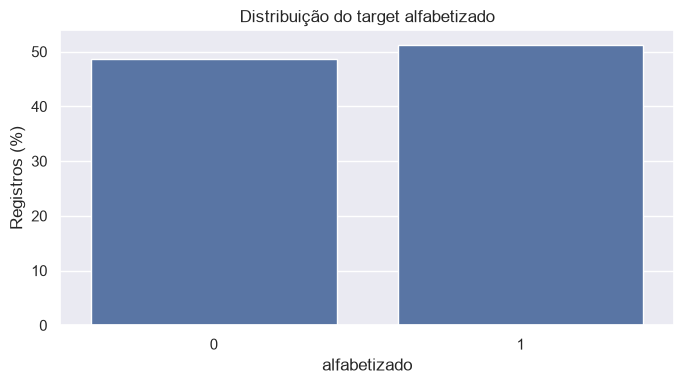

In [33]:
COL_TARGET = "alfabetizado"

if COL_TARGET not in schema.names():
    raise KeyError(f"Target '{COL_TARGET}' não encontrado. Confira as colunas listadas acima.")

dist_target = (
    lf.group_by(COL_TARGET)
      .agg(pl.len().alias("quantidade"))
      .sort(COL_TARGET)
      .collect()
)
dist_target_pd = dist_target.to_pandas()
dist_target_pd["percentual"] = 100 * dist_target_pd["quantidade"] / dist_target_pd["quantidade"].sum()
display(dist_target_pd)

plt.figure(figsize=(7, 4))
sns.barplot(data=dist_target_pd, x=COL_TARGET, y="percentual")
plt.title("Distribuição do target alfabetizado")
plt.ylabel("Registros (%)")
plt.xlabel("alfabetizado")
plt.tight_layout()
plt.show()


## 6. Separação inicial das variáveis

A separação abaixo é automática e serve como ponto de partida. Revise a lista antes de interpretar os resultados: algumas colunas numéricas são códigos, identificadores ou variáveis de controle, e não medidas quantitativas apropriadas para correlação.


In [34]:
colunas = schema.names()
identificadores = [
    c for c in colunas
    if c.lower() in {"id_aluno", "id_escola", "id_municipio", "codigo_do_municipio",
                     "cod_municipio", "sigla_uf", "nome_uf", "nome_do_municipio"}
]
colunas_numericas = [
    nome for nome, dtype in schema.items()
    if dtype.is_numeric() and nome != COL_TARGET
]
colunas_categoricas = [
    nome for nome, dtype in schema.items()
    if dtype == pl.String or dtype == pl.Categorical or dtype == pl.Enum
]

print("Target:", COL_TARGET)
print("Identificadores/códigos candidatos a exclusão das correlações:", identificadores)
print("Variáveis numéricas detectadas:", colunas_numericas)
print("Variáveis categóricas detectadas:", colunas_categoricas)


Target: alfabetizado
Identificadores/códigos candidatos a exclusão das correlações: ['id_aluno', 'id_escola', 'id_municipio', 'sigla_uf']
Variáveis numéricas detectadas: ['id_municipio', 'ano_referencia', 'serie', 'rede', 'presenca', 'preenchimento_caderno', 'proficiencia', 'peso_aluno', 'taxa_alfabetizacao_municipio_ano_anterior', 'media_portugues_municipio_ano_anterior', 'valor_bolsa_familia', 'valor_fundeb', 'valor_receitas', 'valor_pib', 'valor_pib_per_capita', 'qtd_escolas_inse', 'qtd_alunos_inse', 'media_inse', 'pc_nivel_1', 'pc_nivel_2', 'pc_nivel_3', 'pc_nivel_4', 'pc_nivel_5', 'pc_nivel_6', 'pc_nivel_7', 'pc_nivel_8', 'qtd_escolas_censo', 'qt_mat_bas', 'qt_doc_bas', 'qt_tur_bas', 'in_biblioteca_sala_leitura', 'in_laboratorio_informatica', 'in_quadra_esportes', 'in_agua_rede_publica', 'in_energia_rede_publica', 'in_esgoto_rede_publica', 'in_internet', 'in_banda_larga']
Variáveis categóricas detectadas: ['id_aluno', 'id_escola', 'nome_municipio', 'sigla_uf', 'rede_descricao', 'c

## 7. Correlação entre variáveis numéricas

Calculamos a matriz em uma amostra aleatória de até 150 mil registros para manter a análise leve. A correlação de Pearson identifica principalmente relações lineares; não prova causalidade e pode ser influenciada por assimetria e valores extremos.

**Atenção:** a seleção exclui identificadores óbvios, mas revise os nomes impressos na seção anterior e ajuste `excluir_da_correlacao` conforme o dicionário da base.


Registros na amostra: 150000

Valores disponíveis por variável:


pc_nivel_2                                    67983
pc_nivel_5                                    67983
pc_nivel_1                                    67983
media_inse                                    67983
qtd_alunos_inse                               67983
qtd_escolas_inse                              67983
pc_nivel_6                                    67983
pc_nivel_7                                    67983
pc_nivel_8                                    67983
pc_nivel_3                                    67983
pc_nivel_4                                    67983
qt_doc_bas                                    68032
qt_tur_bas                                    68032
in_biblioteca_sala_leitura                    68032
in_laboratorio_informatica                    68032
in_quadra_esportes                            68032
in_agua_rede_publica                          68032
in_energia_rede_publica                       68032
in_esgoto_rede_publica                        68032
qt_mat_bas  

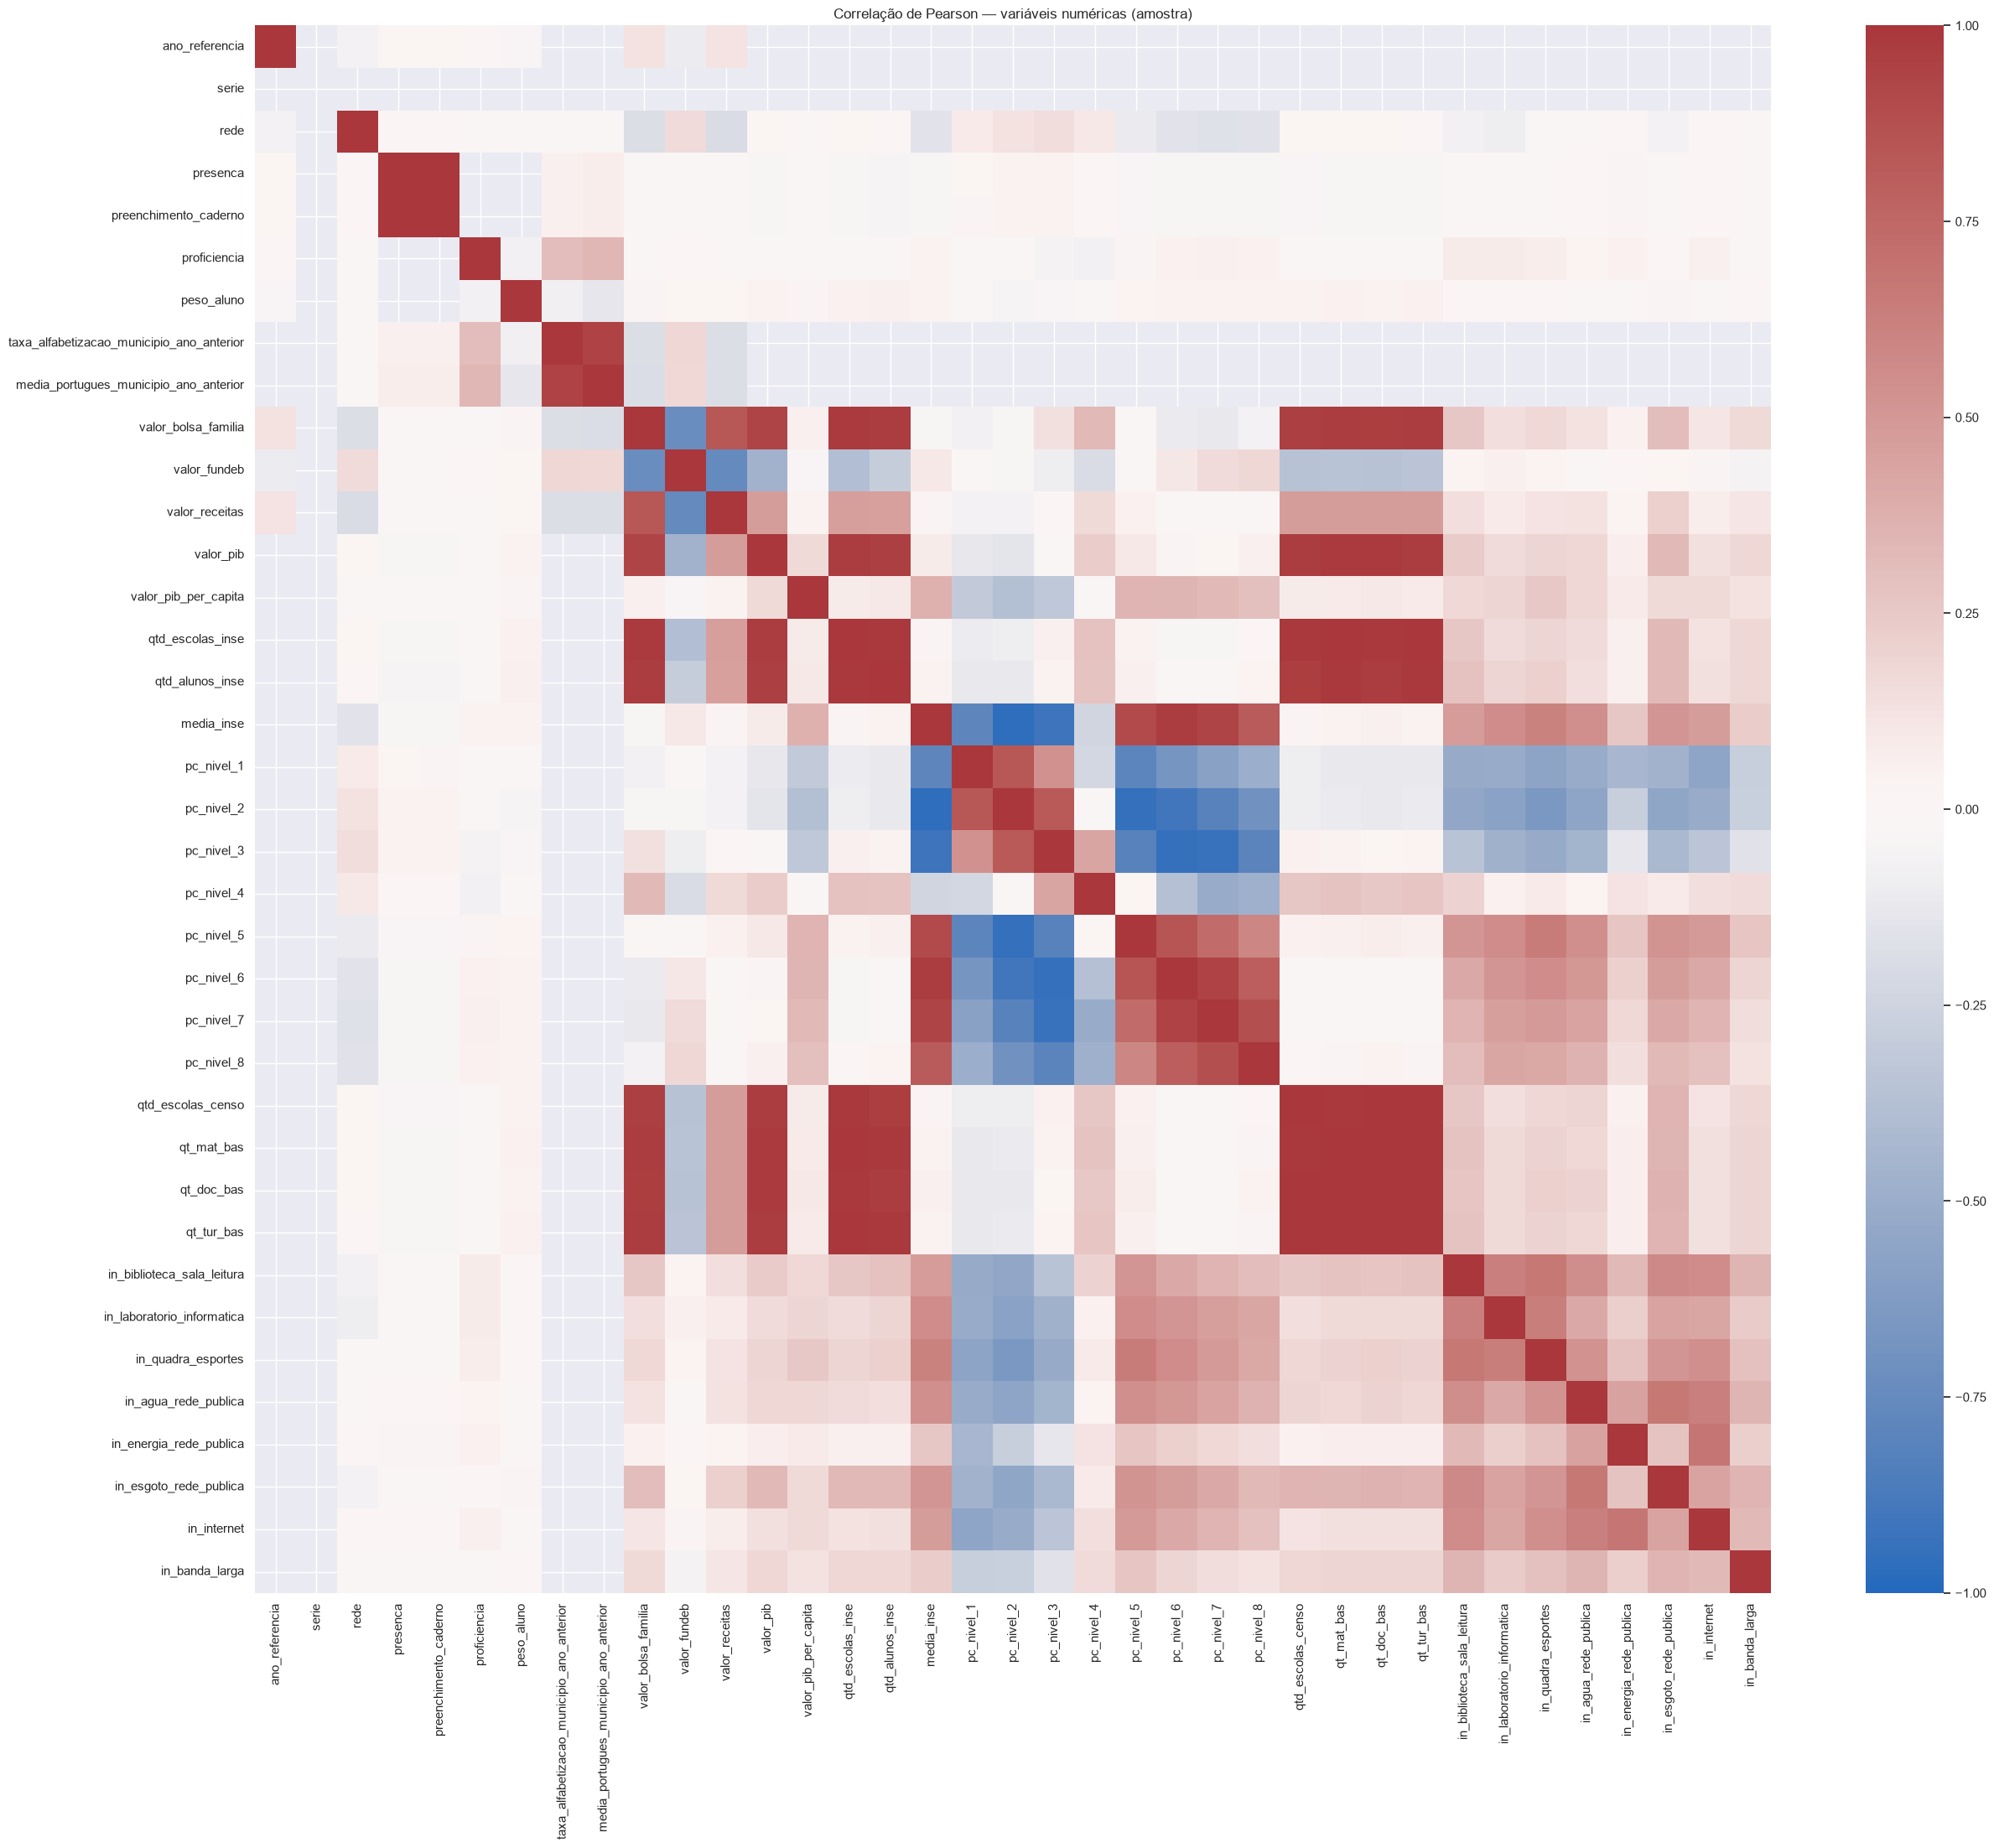

,variavel_1,variavel_2,correlacao,correlacao_abs
990,qt_mat_bas,qt_tur_bas,0.999311,0.999311
115,presenca,preenchimento_caderno,0.998751,0.998751
1027,qt_doc_bas,qt_tur_bas,0.996483,0.996483
544,qtd_escolas_inse,qt_mat_bas,0.996064,0.996064
952,qtd_escolas_censo,qt_doc_bas,0.995306,0.995306
989,qt_mat_bas,qt_doc_bas,0.994814,0.994814
546,qtd_escolas_inse,qt_tur_bas,0.994595,0.994595
953,qtd_escolas_censo,qt_tur_bas,0.993536,0.993536
581,qtd_alunos_inse,qt_mat_bas,0.990669,0.990669
951,qtd_escolas_censo,qt_mat_bas,0.990261,0.990261


In [35]:
N_AMOSTRA = 150_000

excluir_da_correlacao = set(identificadores) | {COL_TARGET}

numericas_correlacao = [
    c for c in colunas_numericas
    if c not in excluir_da_correlacao
]

if len(numericas_correlacao) < 2:
    print("Não há variáveis numéricas suficientes para calcular correlações.")

else:
    # Seleciona as colunas numéricas sem exigir que todas estejam preenchidas.
    # A amostra é feita antes de converter os dados para pandas.
    df_corr = (
        lf.select(numericas_correlacao)
        .collect()
        .to_pandas()
    )

    # Amostra aleatória reproduzível
    df_corr = df_corr.sample(
        n=min(N_AMOSTRA, len(df_corr)),
        random_state=42
    )

    print("Registros na amostra:", len(df_corr))
    print("\nValores disponíveis por variável:")
    display(df_corr.notna().sum().sort_values())

    # Cada correlação usa os pares de valores disponíveis
    # para as duas variáveis analisadas.
    matriz_corr = df_corr.corr(
        numeric_only=True,
        min_periods=2
    )

    plt.figure(figsize=(
        max(10, len(matriz_corr.columns) * 0.7),
        max(8, len(matriz_corr.columns) * 0.6)
    ))

    sns.heatmap(
        matriz_corr,
        cmap="vlag",
        center=0,
        vmin=-1,
        vmax=1
    )

    plt.title("Correlação de Pearson — variáveis numéricas (amostra)")
    plt.tight_layout()
    plt.show()

    # Lista os pares com maiores correlações absolutas
    pares = (
        matriz_corr
        .where(
            np.triu(
                np.ones(matriz_corr.shape),
                k=1
            ).astype(bool)
        )
        .stack()
        .rename("correlacao")
        .reset_index()
    )

    pares.columns = ["variavel_1", "variavel_2", "correlacao"]
    pares["correlacao_abs"] = pares["correlacao"].abs()

    display(
        pares.sort_values(
            "correlacao_abs",
            ascending=False
        ).head(20)
    )

## 8. Relação entre variáveis numéricas e o target

Quando o target é binário (0/1), a correlação ponto-bisserial equivale à correlação de Pearson entre a variável numérica e o target codificado numericamente. Aqui apresentamos a correlação como triagem exploratória, desde que os valores do target sejam realmente binários.

Correlação próxima de zero não exclui uma relação não linear. Variáveis com muitos nulos também podem apresentar resultados enviesados se a análise considerar apenas linhas completas.


Valores distintos do target: [0, 1]


,variavel,correlacao_com_target,abs_correlacao
5,proficiencia,0.795599,0.795599
4,preenchimento_caderno,0.401542,0.401542
3,presenca,0.401007,0.401007
8,media_portugues_municipio_ano_anterior,0.246996,0.246996
7,taxa_alfabetizacao_municipio_ano_anterior,0.235955,0.235955
30,in_laboratorio_informatica,0.072963,0.072963
23,pc_nivel_7,0.069492,0.069492
19,pc_nivel_3,-0.065925,0.065925
22,pc_nivel_6,0.063751,0.063751
20,pc_nivel_4,-0.062518,0.062518


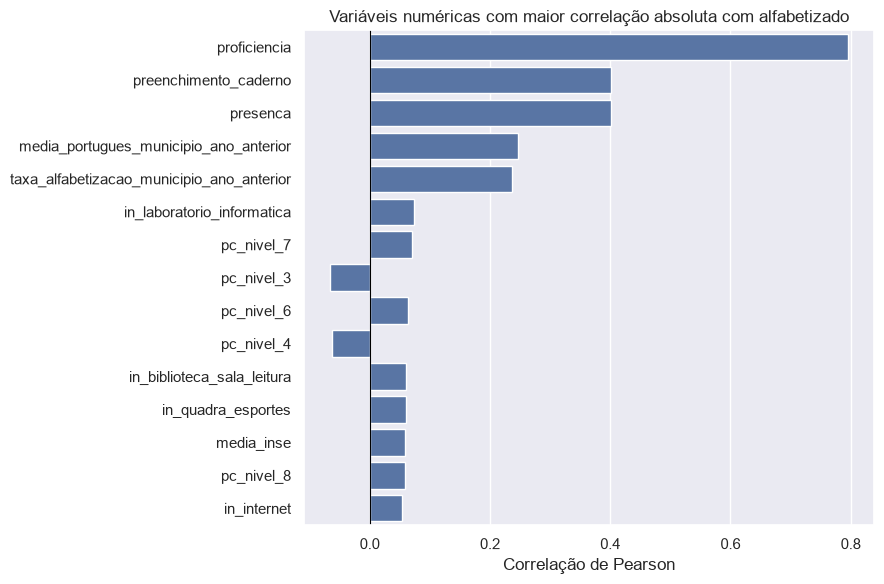

In [36]:
valores_target = (
    lf.select(pl.col(COL_TARGET).drop_nulls().unique())
      .collect()[COL_TARGET]
      .to_list()
)
print("Valores distintos do target:", valores_target)

if set(valores_target).issubset({0, 1, 0.0, 1.0, True, False}) and len(valores_target) == 2:
    cols_target_num = [c for c in numericas_correlacao if c in colunas]
    # Agrega a correlação no Polars para evitar carregar a base completa para pandas.
    exprs = [
        pl.corr(pl.col(c).cast(pl.Float64), pl.col(COL_TARGET).cast(pl.Float64)).alias(c)
        for c in cols_target_num
    ]
    correlacoes_target = lf.select(exprs).collect().to_dicts()[0]
    corr_target_pd = pd.DataFrame({
        "variavel": list(correlacoes_target.keys()),
        "correlacao_com_target": list(correlacoes_target.values())
    })
    corr_target_pd["abs_correlacao"] = corr_target_pd["correlacao_com_target"].abs()
    display(corr_target_pd.sort_values("abs_correlacao", ascending=False))

    top_target = corr_target_pd.dropna().sort_values("abs_correlacao", ascending=False).head(15)
    plt.figure(figsize=(9, 6))
    sns.barplot(data=top_target, x="correlacao_com_target", y="variavel")
    plt.axvline(0, color="black", linewidth=0.8)
    plt.title("Variáveis numéricas com maior correlação absoluta com alfabetizado")
    plt.xlabel("Correlação de Pearson")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()
else:
    print("O target não tem exatamente dois valores binários conforme esperado. Revise a codificação antes de interpretar correlações.")


## 9. Comparação das variáveis numéricas por classe do target

Comparar mediana e média por classe ajuda a perceber diferenças entre alunos classificados como alfabetizados e não alfabetizados. Por ser uma base grande, a tabela agregada é preferível a um gráfico com milhões de pontos.


In [45]:
# Resumo das variáveis numéricas por classe do target
# Usa a lista numericas_correlacao já definida nas seções anteriores.

variaveis_comparacao = [
    nome
    for nome, dtype in schema.items()
    if dtype.is_numeric()
    and nome != COL_TARGET
    and nome not in identificadores
]

resumo_por_target = (
    lf.group_by(COL_TARGET)
    .agg(
        [
            pl.col(c).mean().alias(f"{c}_media")
            for c in variaveis_comparacao
        ]
        + [
            pl.col(c).median().alias(f"{c}_mediana")
            for c in variaveis_comparacao
        ]
        + [
            pl.col(c).std().alias(f"{c}_desvio_padrao")
            for c in variaveis_comparacao
        ]
    )
    .sort(COL_TARGET)
    .collect()
    .to_pandas()
)

# Transpor: estatísticas nas linhas e classes nas colunas
resumo_por_target_long = (
    resumo_por_target
    .set_index(COL_TARGET)
    .T
    .reset_index()
    .rename(columns={"index": "variavel_estatistica"})
)

display(resumo_por_target_long)



alfabetizado,variavel_estatistica,0,1
0,ano_referencia_media,2023.538076,2023.557870
1,serie_media,2.000000,2.000000
2,rede_media,2.891706,2.883396
3,presenca_media,0.728078,1.000000
4,preenchimento_caderno_media,0.727448,1.000000
...,...,...,...
106,in_agua_rede_publica_desvio_padrao,0.251780,0.233627
107,in_energia_rede_publica_desvio_padrao,0.093501,0.071569
108,in_esgoto_rede_publica_desvio_padrao,0.340856,0.336078
109,in_internet_desvio_padrao,0.136428,0.120388


## 10. Relações com variáveis categóricas

Para evitar gráficos ilegíveis, analisamos apenas variáveis categóricas com cardinalidade baixa. As categorias são agrupadas por target e mostramos as proporções dentro de cada categoria. Códigos de alta cardinalidade e identificadores não devem ser tratados como categorias comuns.


Categóricas de baixa cardinalidade: [('rede_descricao', 3), ('dataset_split', 3)]


,rede_descricao,alfabetizado,quantidade,percentual_na_categoria
5,Estadual,0,203976,46.848171
2,Estadual,1,231422,53.151829
0,Municipal,0,1679468,48.927336
4,Municipal,1,1753108,51.072664
1,Privada,0,9,36.000000
3,Privada,1,16,64.000000


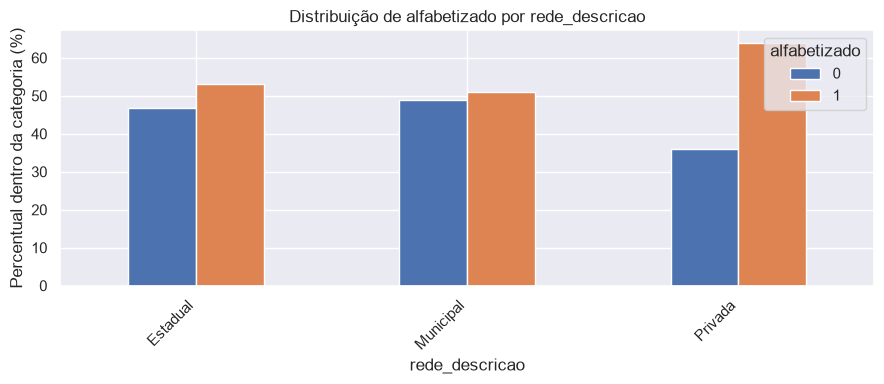

,dataset_split,alfabetizado,quantidade,percentual_na_categoria
1,teste,0,282888,48.639949
4,teste,1,298708,51.360051
5,treino,0,1317452,48.699788
0,treino,1,1387800,51.300212
2,validacao,0,283113,48.715910
3,validacao,1,298038,51.284090


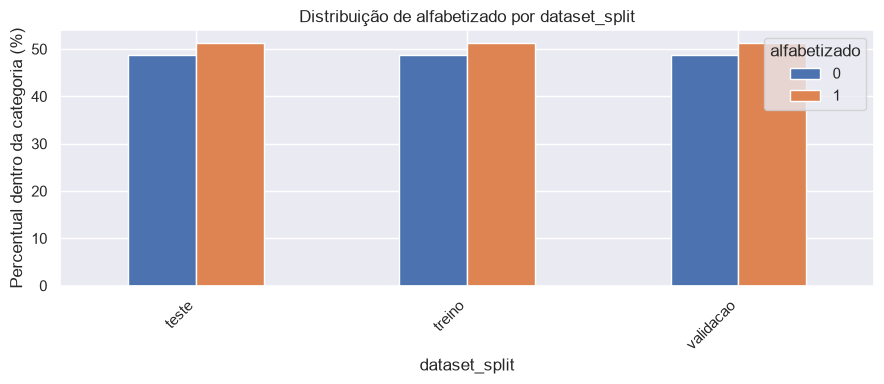

In [38]:
MAX_CATEGORIAS = 12
MAX_CATEGORICAS = 5

candidatas_cat = []
for c in colunas_categoricas:
    n_cat = (
        lf.select(pl.col(c).n_unique().alias("n"))
          .collect()["n"][0]
    )
    if 2 <= n_cat <= MAX_CATEGORIAS and c not in identificadores and c != COL_TARGET:
        candidatas_cat.append((c, n_cat))

print("Categóricas de baixa cardinalidade:", candidatas_cat)

for c, n_cat in candidatas_cat[:MAX_CATEGORICAS]:
    tab = (
        lf.group_by([c, COL_TARGET])
          .agg(pl.len().alias("quantidade"))
          .collect()
          .to_pandas()
    )
    tab["percentual_na_categoria"] = (
        tab["quantidade"] / tab.groupby(c)["quantidade"].transform("sum") * 100
    )
    display(tab.sort_values([c, COL_TARGET]))

    pivot = tab.pivot(index=c, columns=COL_TARGET, values="percentual_na_categoria").fillna(0)
    pivot.plot(kind="bar", figsize=(9, 4))
    plt.title(f"Distribuição de alfabetizado por {c}")
    plt.ylabel("Percentual dentro da categoria (%)")
    plt.xlabel(c)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


## 11. Inspeção de relações específicas

Use esta seção para investigar hipóteses levantadas nos gráficos. Por exemplo, compare indicadores socioeconômicos, infraestrutura escolar e contexto municipal. Ajuste os nomes conforme as colunas reais impressas na seção 2.

A tabela abaixo permite verificar se nomes de variáveis de interesse estão presentes sem gerar erro caso algum deles não exista.


In [41]:
variaveis_interesse = [
    "media_inse",
    "valor_pib_per_capita",
    "valor_fundeb",
    "valor_receitas",
    "taxa_alfabetizacao_municipio_ano_anterior",
    "media_portugues_municipio_ano_anterior",
    "proficiencia",
    "peso_aluno",
]
presentes = [c for c in variaveis_interesse if c in colunas]
ausentes = [c for c in variaveis_interesse if c not in colunas]

print("Variáveis de interesse presentes:", presentes)
print("Variáveis de interesse não encontradas:", ausentes)


Variáveis de interesse presentes: ['media_inse', 'valor_pib_per_capita', 'valor_fundeb', 'valor_receitas', 'taxa_alfabetizacao_municipio_ano_anterior', 'media_portugues_municipio_ano_anterior', 'proficiencia', 'peso_aluno']
Variáveis de interesse não encontradas: []


## 12. Registro dos principais achados

Preencha esta seção após executar e interpretar os resultados. Evite registrar apenas valores de correlação: descreva o padrão observado, a limitação e o que precisa ser verificado.


In [42]:
achados = pd.DataFrame([
    {
        "tema": "Distribuição do target",
        "observacao": (
            "As classes estão relativamente equilibradas: "
            "51,31% dos registros pertencem à classe 1 e 48,69% à classe 0."
        ),
        "limitacao/validacao": (
            "A classificação foi recebida pronta na base original. "
            "Sua regra de construção não foi reproduzida neste notebook."
        )
    },
    {
        "tema": "Relações entre variáveis numéricas",
        "observacao": (
            "Foram identificadas correlações elevadas entre algumas "
            "variáveis de volume e estrutura educacional, indicando "
            "possível sobreposição de informações."
        ),
        "limitacao/validacao": (
            "A correlação de Pearson identifica principalmente relações "
            "lineares e não comprova causalidade."
        )
    },
    {
        "tema": "Relações com o target",
        "observacao": (
            "As maiores correlações positivas foram observadas em "
            "proficiencia (0,795599), preenchimento_caderno (0,401542), "
            "presenca (0,401007), media_portugues_municipio_ano_anterior "
            "(0,246996) e taxa_alfabetizacao_municipio_ano_anterior (0,235955)."
        ),
        "limitacao/validacao": (
            "As associações não comprovam causalidade. A relação entre "
            "proficiencia e alfabetizado deve ser avaliada antes da "
            "modelagem para verificar possível vazamento de informação."
        )
    },
    {
        "tema": "Variáveis categóricas",
        "observacao": (
            "As proporções das classes são semelhantes nas redes estadual "
            "e municipal. Na rede privada, 64% dos registros pertencem "
            "à classe 1."
        ),
        "limitacao/validacao": (
            "A rede privada possui apenas 25 registros, quantidade "
            "insuficiente para conclusões robustas. dataset_split é "
            "uma variável de controle, não um preditor."
        )
    },
    {
        "tema": "Valores ausentes e cobertura temporal",
        "observacao": (
            "As análises anteriores identificaram valores ausentes em "
            "parte das variáveis da base."
        ),
        "limitacao/validacao": (
            "A cobertura e a disponibilidade temporal devem ser verificadas "
            "antes da seleção das variáveis para modelagem."
        )
    },
    {
        "tema": "Possível redundância entre variáveis",
        "observacao": (
            "A matriz de correlação mostrou associações elevadas entre "
            "algumas variáveis relacionadas a quantidades de escolas, "
            "alunos e estrutura educacional."
        ),
        "limitacao/validacao": (
            "É necessário avaliar a sobreposição de informações e o "
            "significado das variáveis antes de selecionar as features."
        )
    },
    {
        "tema": "Possível data leakage",
        "observacao": (
            "A elevada correlação entre proficiencia e alfabetizado "
            "merece investigação antes da construção dos modelos."
        ),
        "limitacao/validacao": (
            "A correlação, isoladamente, não comprova vazamento. "
            "É necessário avaliar a origem das variáveis e sua "
            "disponibilidade no momento da previsão."
        )
    }
])

display(achados)



,tema,observacao,limitacao/validacao
0,Distribuição do target,"As classes estão relativamente equilibradas: 51,31% dos registros pertencem à classe 1 e 48,69% à classe 0.",A classificação foi recebida pronta na base original. Sua regra de construção não foi reproduzida neste notebook.
1,Relações entre variáveis numéricas,"Foram identificadas correlações elevadas entre algumas variáveis de volume e estrutura educacional, indicando possív...",A correlação de Pearson identifica principalmente relações lineares e não comprova causalidade.
2,Relações com o target,"As maiores correlações positivas foram observadas em proficiencia (0,795599), preenchimento_caderno (0,401542), pres...",As associações não comprovam causalidade. A relação entre proficiencia e alfabetizado deve ser avaliada antes da mod...
3,Variáveis categóricas,"As proporções das classes são semelhantes nas redes estadual e municipal. Na rede privada, 64% dos registros pertenc...","A rede privada possui apenas 25 registros, quantidade insuficiente para conclusões robustas. dataset_split é uma var..."
4,Valores ausentes e cobertura temporal,As análises anteriores identificaram valores ausentes em parte das variáveis da base.,A cobertura e a disponibilidade temporal devem ser verificadas antes da seleção das variáveis para modelagem.
5,Possível redundância entre variáveis,"A matriz de correlação mostrou associações elevadas entre algumas variáveis relacionadas a quantidades de escolas, a...",É necessário avaliar a sobreposição de informações e o significado das variáveis antes de selecionar as features.
6,Possível data leakage,A elevada correlação entre proficiencia e alfabetizado merece investigação antes da construção dos modelos.,"A correlação, isoladamente, não comprova vazamento. É necessário avaliar a origem das variáveis e sua disponibilidad..."


## 13. Conclusão

As análises exploratórias realizadas neste notebook permitiram investigar as relações entre as variáveis da base consolidada e o target `alfabetizado`, complementando as análises de distribuição e de valores ausentes realizadas anteriormente.

A análise de correlação identificou associações positivas entre `alfabetizado` e as variáveis `proficiencia`, `preenchimento_caderno`, `presenca`, `media_portugues_municipio_ano_anterior` e `taxa_alfabetizacao_municipio_ano_anterior`. Entre elas, `proficiencia` apresentou a maior correlação. Esses resultados contribuem para identificar relações que merecem investigação nas próximas etapas, mas não comprovam causalidade.

A comparação entre as classes do target também mostrou diferenças nas médias de algumas variáveis educacionais. Na análise das variáveis categóricas, as proporções das classes foram semelhantes nas redes estadual e municipal. Os resultados da rede privada devem ser interpretados com cautela, devido à pequena quantidade de registros observados.

A interpretação dos resultados deve considerar os valores ausentes, a cobertura temporal e a possível redundância entre variáveis. A relação entre `proficiencia` e `alfabetizado` também requer atenção antes da modelagem, para avaliar a origem das informações e o possível risco de *data leakage*.

Conclui-se que o TC3-46 contribui para o entendimento inicial das relações presentes na base e fornece subsídios para as próximas etapas do projeto. A seleção definitiva das variáveis para os modelos deverá considerar sua qualidade, seu significado, sua disponibilidade no momento da previsão e sua adequação aos objetivos de negócio.